# Course Recommendation System (CRS) - Enhanced with a Personalized Recommendation Engine

**Project:** MCA mini/major project | **Language:** Python | **Core idea:** content-based filtering

This notebook keeps your original CRS and adds a **Personalized Course Recommendation Engine**.

| Part | What it contains |
|---|---|
| 1 | Setup and loading the data (original imports kept) |
| 2 | **Dataset audit** - what the uploaded file really contains |
| 3 | **Original CRS preserved** (CountVectorizer + cosine similarity) with small, explained fixes |
| 4 | **New:** cleaning pipeline, TF-IDF index, scoring and ranking engine |
| 5 | **New:** student input interface |
| 6 | **New:** personalised recommendations, explanations, learning path, fallback |
| 7 | **New:** testing and comparison with the original method |
| 8 | Limitations and viva notes |

**How to run:** put the CSV in the same folder as this notebook, then *Kernel -> Restart & Run All*.
The outputs saved in this file were produced by running it on the uploaded dataset.

> **Honesty note.** No real student interaction data or relevance labels exist, so nothing here claims a
> validated "accuracy". Student profiles used for testing are **synthetic sample profiles**.

## Part 1 - Setup and loading

The imports from your original notebook are kept. Two small safety nets were added:
* `neattext` and `seaborn` are imported inside `try/except`, so the notebook still runs if one is missing
  (a simple stand-in with the same two functions is used for `neattext`; install it via `requirements.txt` to use the real one).
* The CSV name is searched for automatically (your description says `udemy_courses.csv`; the uploaded file is `UdemyCleanedTitle_new.csv`).

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd

try:
    import neattext.functions as nfx
    print("neattext found - using the real library.")
except ImportError:
    # Minimal stand-in that offers the same two functions the original notebook uses.
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    class _NeatTextStandIn:
        @staticmethod
        def remove_stopwords(text):
            return " ".join(w for w in str(text).split() if w.lower() not in ENGLISH_STOP_WORDS)
        @staticmethod
        def remove_special_characters(text):
            return re.sub(r"[^\w\s]", "", str(text))
    nfx = _NeatTextStandIn()
    print("neattext not installed - using a simple stand-in (pip install neattext to use the real one).")

try:
    import seaborn as sn          # imported in the original notebook
except ImportError:
    sn = None

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
warnings.filterwarnings("ignore", category=FutureWarning)

neattext not installed - using a simple stand-in (pip install neattext to use the real one).


In [2]:
# Look for the dataset next to the notebook (first match wins).
CANDIDATE_FILES = ["udemy_courses.csv", "UdemyCleanedTitle_new.csv", "UdemyCleanedTitle.csv"]
DATA_PATH = next((f for f in CANDIDATE_FILES if os.path.exists(f)), None)
assert DATA_PATH, f"Put your dataset in this folder. Looked for: {CANDIDATE_FILES}"
print("Using dataset file:", DATA_PATH)

# ORIGINAL STEP: load the data exactly as before. df_raw is never modified afterwards.
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()          # the original notebook's working copy (used by Part 3)
df.head()

Using dataset file: UdemyCleanedTitle_new.csv


,course_id,course_title,url,price,num_subscribers,num_reviews,num_lectures,level,content_duration,Rating,published_timestamp,subject,Platform,Unnamed: 13
0,1070968,Ultimate Investment Banking Course,https://www.udemy.com/ultimate-investment-banking-course/,200,2147,23,51,All Levels,1.5 hours,0.69,2017-01-18T20:58:58Z,Business Finance,Udemy,NaN
1,1113822,Complete GST Course & Certification - Grow Your CA Practice,https://www.udemy.com/goods-and-services-tax/,75,2792,923,274,All Levels,39 hours,0.11,2017-03-09T16:34:20Z,Business Finance,Udemy,NaN
2,1006314,Financial Modeling for Business Analysts and Consultants,https://www.udemy.com/financial-modeling-for-business-analysts-and-consultants/,45,2174,74,51,Intermediate Level,2.5 hours,0.89,2016-12-19T19:26:30Z,Business Finance,Udemy,NaN
3,1210588,Beginner to Pro - Financial Analysis in Excel 2017,https://www.udemy.com/complete-excel-finance-course-from-beginner-to-pro/,95,2451,11,36,All Levels,3 hours,0.96,2017-05-30T20:07:24Z,Business Finance,Udemy,NaN
4,1011058,How To Maximize Your Profits Trading Options,https://www.udemy.com/how-to-maximize-your-profits-trading-options/,200,1276,45,26,Intermediate Level,2 hours,0.88,2016-12-13T14:57:18Z,Business Finance,Udemy,NaN


## Part 2 - Dataset audit (verify before trusting)

The task description mentions ~3,683 Udemy courses with columns such as `is_paid`. Before building anything,
the actual file is checked against that description.

In [3]:
expected_from_description = ["course_id", "course_title", "url", "is_paid", "price", "num_subscribers",
                             "num_reviews", "num_lectures", "level", "content_duration",
                             "published_timestamp", "subject"]
cols = list(dict.fromkeys(expected_from_description + list(df_raw.columns)))
audit = pd.DataFrame({
    "column": cols,
    "mentioned_in_description": [c in expected_from_description for c in cols],
    "present_in_file": [c in df_raw.columns for c in cols],
    "dtype_as_loaded": [str(df_raw[c].dtype) if c in df_raw.columns else "-" for c in cols],
    "missing_values": [int(df_raw[c].isna().sum()) if c in df_raw.columns else "-" for c in cols],
})
audit

,column,mentioned_in_description,present_in_file,dtype_as_loaded,missing_values
0,course_id,True,True,str,4
1,course_title,True,True,str,2
2,url,True,True,str,2
3,is_paid,True,False,-,-
4,price,True,True,str,8
5,num_subscribers,True,True,str,6
6,num_reviews,True,True,str,6
7,num_lectures,True,True,str,6
8,level,True,True,str,6
9,content_duration,True,True,str,0


In [4]:
print("Rows x columns in the file :", df_raw.shape)
print("Exact duplicate rows       :", int(df_raw.duplicated().sum()))
print("Duplicate course_id values :", int(df_raw["course_id"].duplicated().sum()))
print("Duplicate URLs             :", int(df_raw["url"].duplicated().sum()))
print()
print("Courses per platform:")
print(df_raw["Platform"].value_counts(dropna=False).to_string())
print()
udemy = df_raw[df_raw["Platform"] == "Udemy"]
print(f"Udemy rows: {len(udemy)}  |  unique Udemy URLs: {udemy['url'].nunique()}  "
      "-> the Udemy block appears to be stored twice.")
print()
print("Numeric-looking columns were loaded as text because of stray values:")
for c in ["price", "num_subscribers", "num_reviews", "num_lectures"]:
    bad = df_raw[c][pd.to_numeric(df_raw[c], errors="coerce").isna() & df_raw[c].notna()].unique()
    print(f"  {c:16s} non-numeric values: {list(bad)}")

Rows x columns in the file : (14286, 14)
Exact duplicate rows       : 31
Duplicate course_id values : 10607
Duplicate URLs             : 4101

Courses per platform:
Platform
Udemy       7682
Coursera    3522
Edx         3082

Udemy rows: 7682  |  unique Udemy URLs: 3678  -> the Udemy block appears to be stored twice.

Numeric-looking columns were loaded as text because of stray values:
  price            non-numeric values: ['Free', 'TRUE', 'hour']
  num_subscribers  non-numeric values: ['hour']
  num_reviews      non-numeric values: ['hour']
  num_lectures     non-numeric values: ['hour']


In [5]:
# Is the 'subject' column trustworthy on every platform?
tmp = df_raw.assign(subject=df_raw["subject"].str.strip())
print(pd.crosstab(tmp["Platform"], tmp["subject"].fillna("(missing)")))
print()
print("Sample of edX rows - does the subject agree with the title?")
tmp[tmp["Platform"] == "Edx"].sample(6, random_state=2)[["course_title", "subject", "level", "price"]]

subject   (missing)  Business Finance  Graphic Design  Musical Instruments  Web Development  hour
Platform                                                                                         
Coursera       3522                 0               0                    0                0     0
Edx               0              1049             105                   72             1856     0
Udemy             0              2593            1305                  750             3032     2

Sample of edX rows - does the subject agree with the title?


,course_title,subject,level,price
7912,"Mechanics, Part 2…",Business Finance,Expert Level,30
8769,Enterprise DataManagement…,Web Development,Beginner Level,25
8018,Natural Disasters…,Business Finance,Beginner Level,95
9780,Social Welfare Policy andServices…,Web Development,All Levels,195
9407,Comprendre larespiration…,Web Development,Intermediate Level,20
8277,"A-level Mathematics forYear 12 - Course 1:Algebraic Methods, Gra……",Business Finance,All Levels,50


In [6]:
# Is the 'Rating' column a usable rating?
num = df_raw.assign(Rating=pd.to_numeric(df_raw["Rating"], errors="coerce"),
                    num_reviews=pd.to_numeric(df_raw["num_reviews"], errors="coerce"))
print("Rating range:", num["Rating"].min(), "to", num["Rating"].max())
print("Mean Rating of courses with ZERO reviews :", round(num.loc[num["num_reviews"] == 0, "Rating"].mean(), 2))
print("Mean Rating of courses with reviews      :", round(num.loc[num["num_reviews"] > 0, "Rating"].mean(), 2))
print("Spearman correlation Rating vs num_reviews:", round(num["Rating"].corr(num["num_reviews"], method="spearman"), 2))

Rating range: 0.0 to 1.0
Mean Rating of courses with ZERO reviews : 0.74
Mean Rating of courses with reviews      : 0.67
Spearman correlation Rating vs num_reviews: -0.15


### What the audit means for the project (for the uploaded file)

| Finding | Decision taken |
|---|---|
| File has **14,286 rows from three platforms** (Udemy, Coursera, edX), not 3,683 Udemy courses. The Udemy block is stored **twice**. | Duplicates are removed by URL; platform is kept as a column and can be used as a filter. |
| **No `is_paid` column.** | `is_paid` is **derived** from `price` (price > 0). Possible because every price is numeric or "Free". |
| A **`Rating`** column exists, but courses with *zero reviews* have a **higher** average rating than courses with reviews, and the scale is 0-1. | It does **not** behave like a real rating, so it is **not used for ranking** and is not shown as a quality measure. |
| `subject` has only **4 values** and is **missing for all Coursera rows**; on edX rows it contradicts the title (e.g. a jazz course labelled *Business Finance*). | `subject` is trusted **only for Udemy rows**. For other platforms topic matching relies on the title. |
| **No Data-Science / AI / Python subject exists** - topics like these can only be found through titles. | Free-text interests and skills are matched against titles with TF-IDF. |
| Price, level, duration and subscriber figures on Coursera/edX rows use the same value patterns as Udemy and cannot be verified here. | Results from those platforms carry a visible **"unverified metadata"** caution. A `platforms=["Udemy"]` filter is available. |
| Some edX titles are damaged (all end with "..." and words are fused, e.g. `withPython`). | The original title is kept for display; a cleaned copy (`match_title`) is used only for matching. |
| 5 malformed rows (missing title, broken CSV quoting, stray header text such as `hour`). | Removed and counted in the cleaning log. |

## Part 3 - Original CRS (preserved)

Your original steps are kept in order. Only the changes listed below were made; each is also marked with `# FIX` in the code.

| # | Change | Why |
|---|---|---|
| 1 | Rows without a title are dropped before cleaning | `neattext` raises an error on missing text. |
| 2 | `get_feature_names()` -> `get_feature_names_out()` | The old method was removed in recent scikit-learn. |
| 3 | The dense word table is shown for 5 rows only | Converting the whole matrix to a DataFrame needs several GB on 14,000+ courses. |
| 4 | Similarity is computed **per query** (one row) instead of building the full course-by-course matrix | The full matrix needs about 1.6 GB here. The numbers are identical (checked below). The full matrix is still available with `BUILD_DENSE_MATRIX = True`. |
| 5 | `num_subscribers` converted to numbers before sorting | In this file it is text, so sorting would be alphabetical ("99" > "268923"). |
| 6 | `.copy()` before adding `Similarity_Score` | Avoids pandas' `SettingWithCopyWarning`. |
| 7 | The final `to_csv` is behind a switch (`SAVE_CLEANED`) | Avoid writing files unexpectedly. |

In [7]:
# ORIGINAL: course titles of a few rows
df["course_title"].iloc[1:5]

,course_title
1,Complete GST Course & Certification - Grow Your CA Practice
2,Financial Modeling for Business Analysts and Consultants
3,Beginner to Pro - Financial Analysis in Excel 2017
4,How To Maximize Your Profits Trading Options


In [8]:
# ORIGINAL: generate clean text by removing stop-words and special characters
# FIX 1: drop rows that have no title (neattext cannot process missing values)
df = df.dropna(subset=["course_title"]).reset_index(drop=True)

df["Clean_title"] = df["course_title"].apply(nfx.remove_stopwords)
df["Clean_title"] = df["Clean_title"].apply(nfx.remove_special_characters)
df["Clean_title"].iloc[1:5]

,Clean_title
1,Complete GST Course Certification Grow CA Practice
2,Financial Modeling Business Analysts Consultants
3,Beginner Pro Financial Analysis Excel 2017
4,Maximize Profits Trading Options


In [9]:
# ORIGINAL: vectorize the course titles with CountVectorizer
countvect = CountVectorizer()
cv_mat = countvect.fit_transform(df["Clean_title"])
print("Sparse count matrix:", cv_mat.shape, "(courses x distinct words)")

# FIX 2 + 3: get_feature_names_out(), and show only 5 rows instead of the whole dense table
df_cv_words = pd.DataFrame(cv_mat[:5].todense(), columns=countvect.get_feature_names_out())
df_cv_words.loc[:, (df_cv_words != 0).any(axis=0)]

Sparse count matrix: (14284, 10788) (courses x distinct words)


,2017,analysis,analysts,banking,beginner,business,ca,certification,complete,consultants,course,excel,financial,grow,gst,investment,maximize,modeling,options,practice,pro,profits,trading,ultimate
0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,1,1,1,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0
2,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0
3,1,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,0


In [10]:
# ORIGINAL: cosine similarity matrix  (FIX 4: optional - it is huge on this dataset)
n_courses = cv_mat.shape[0]
print(f"A dense {n_courses} x {n_courses} float64 matrix needs about {n_courses**2 * 8 / 1e9:.1f} GB of RAM.")

BUILD_DENSE_MATRIX = False      # set True only if your computer has enough memory
if BUILD_DENSE_MATRIX:
    cosine_sim_mat = cosine_similarity(cv_mat)

A dense 14284 x 14284 float64 matrix needs about 1.6 GB of RAM.


In [11]:
# ORIGINAL: map each title to its row number
course_index = pd.Series(df.index, index=df["course_title"]).drop_duplicates()

# ORIGINAL: simple keyword search + top courses by subscribers
temp = df[df["course_title"].str.contains("Python")]

# FIX 5: num_subscribers is text in this file -> convert before sorting
df["num_subscribers"] = pd.to_numeric(df["num_subscribers"], errors="coerce")
temp = df[df["course_title"].str.contains("Python")]
top6 = temp.sort_values(by="num_subscribers", ascending=False).head(6)
top6[["course_title", "Platform", "num_subscribers"]]

,course_title,Platform,num_subscribers
11001,"Applied Plotting, Charting & Data Representation in Python",Coursera,83737.0
14274,Mining Data to Extract and Visualize Insights in Python,Coursera,50855.0
14279,"Capstone: Retrieving, Processing, and Visualizing Data with Python",Coursera,47652.0
5509,Web Programming with Python,Udemy,35267.0
2502,Web Programming with Python,Udemy,35267.0
6722,Web Programming with Python,Udemy,35267.0


In [12]:
# ORIGINAL: step-by-step similarity for one course (same logic, one matrix row at a time)
index = course_index["How To Maximize Your Profits Trading Options"]
index = index.iloc[0] if hasattr(index, "iloc") else index          # a title can occur more than once

scores = list(enumerate(cosine_similarity(cv_mat[index], cv_mat).ravel()))
sorted_score = sorted(scores, key=lambda x: x[1], reverse=True)
sorted_indices = [i[0] for i in sorted_score[1:]]
sorted_values = [i[1] for i in sorted_score[1:]]
print("First 5 similarity values:", [round(float(v), 3) for v in sorted_values[:5]])

First 5 similarity values: [1.0, 0.577, 0.577, 0.577, 0.577]


In [13]:
# ORIGINAL: recommend_course(title, numrec)
def recommend_course(title, numrec=10):
    idx = course_index[title]
    idx = idx.iloc[0] if hasattr(idx, "iloc") else idx

    # FIX 4: one row of the similarity matrix, computed on demand (identical numbers)
    scores = list(enumerate(cosine_similarity(cv_mat[idx], cv_mat).ravel()))
    sorted_scores = sorted(scores, key=lambda x: x[1], reverse=True)

    selected_course_index = [i[0] for i in sorted_scores[1:]]
    selected_course_score = [i[1] for i in sorted_scores[1:]]

    rec_df = df.iloc[selected_course_index].copy()                 # FIX 6
    rec_df["Similarity_Score"] = selected_course_score

    final_recommended_courses = rec_df[["course_title", "Similarity_Score", "url", "price", "num_subscribers"]]
    return final_recommended_courses.head(numrec)


ans = recommend_course("Trading Options Basics", 10)
ans

,course_title,Similarity_Score,url,price,num_subscribers
5363,Trading Options Basics,1.000000,https://www.udemy.com/trading-options-basics/,200,8.0
97,Options Trading 101: The Basics,0.866025,https://www.udemy.com/options-trading-101-the-basics/,Free,1514.0
4601,Options Trading 101: The Basics,0.866025,https://www.udemy.com/options-trading-101-the-basics/,0,1514.0
195,Trading Options For Consistent Returns: Options Basics,0.816497,https://www.udemy.com/trading-options-for-income/,Free,4077.0
864,Basics of Trading,0.816497,https://www.udemy.com/basicsoftrading/,40,99.0
4393,Trading Options For Consistent Returns: Options Basics,0.816497,https://www.udemy.com/trading-options-for-income/,0,4077.0
5116,Basics of Trading,0.816497,https://www.udemy.com/basicsoftrading/,40,99.0
7329,Trading Options For Consistent Returns: Options Basics,0.816497,https://www.udemy.com/trading-options-for-income/,0,4077.0
11223,Trading Basics,0.816497,https://www.coursera.org/learn/trading-basics,120,10917.0
66,Options Trading Basics (3-Course Bundle),0.774597,https://www.udemy.com/learn-options-trading-courses/,180,10100.0


In [14]:
# Proof for FIX 4: the on-demand row equals the row of the full dense matrix (checked on a 2,000-course sample)
sample = cv_mat[:2000]
dense_sample = cosine_similarity(sample)
on_demand = np.vstack([cosine_similarity(sample[i], sample).ravel() for i in (0, 10, 500, 1999)])
print("Max difference between the two methods:", float(np.abs(dense_sample[[0, 10, 500, 1999]] - on_demand).max()))
print("ans.shape =", ans.shape, "| ans.columns =", list(ans.columns))

# ORIGINAL last step: save the cleaned data (FIX 7: off by default)
SAVE_CLEANED = False
if SAVE_CLEANED:
    df.to_csv("UdemyCleanedTitle.csv", index=None)

Max difference between the two methods: 0.0
ans.shape = (10, 5) | ans.columns = ['course_title', 'Similarity_Score', 'url', 'price', 'num_subscribers']


### Observations about the original method (used later in the comparison)

* It needs an **existing course title** as input - a student cannot describe interests, skills, level, career or budget.
* The only text used is the cleaned title; **no price, level, duration or popularity** information influences the result.
* The same course can be recommended several times (the duplicated Udemy block): in the output above "Options Trading 101: The Basics" and "Trading Options For Consistent Returns..." each appear more than once.
* `CountVectorizer` counts words equally, so very common words weigh as much as rare, informative ones. **TF-IDF** fixes this.

## Part 4 - Enhanced engine: cleaning, TF-IDF index and ranking

The engine is split into small cells. The same code is saved in `crs_engine.py` for the optional Streamlit app.

### 4.1 Configuration: weights and assumptions
**All weights below are design choices by the developer - they are not learned from data and not scientifically validated.**
They are placed in one dictionary so they can be changed and their effect observed (see the ablation in Part 7).

In [15]:
import re
import difflib
from dataclasses import dataclass, field
from typing import Optional, List, Dict, Union

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

# ----------------------------------------------------------------------------
# CONFIGURATION (everything a student may want to tune lives here)
# ----------------------------------------------------------------------------
# Weights are DESIGN CHOICES made by the developer, not values learned from data
# or scientifically validated. Change them and re-run to see the effect.
DEFAULT_WEIGHTS = {
    "interest_match":      0.25,  # title/subject text similarity to the student's interests
    "desired_skill_match": 0.30,  # similarity to skills the student WANTS to learn (strongest signal)
    "career_match":        0.10,  # similarity to keywords associated with the career goal
    "subject_match":       0.08,  # course subject is one of the subjects the student selected
    "level_fit":           0.12,  # how well the course level suits the preferred level
    "duration_fit":        0.05,  # course length vs. the time the student has (only if requested)
    "popularity":          0.10,  # log-scaled subscriber count (kept small on purpose)
    "known_skill_penalty": 0.10,  # subtracted when a course only repeats skills already known
}
WEIGHT_PURPOSE = {
    "interest_match":      "Rewards courses whose text overlaps with the student's interests.",
    "desired_skill_match": "Rewards courses about the skills the student wants to learn.",
    "career_match":        "Rewards courses matching keywords linked to the career goal (hand-written map).",
    "subject_match":       "Small bonus when the dataset's subject equals a subject the student picked.",
    "level_fit":           "1.0 exact level, 0.7 'All Levels', 0.3 adjacent level, 0 otherwise.",
    "duration_fit":        "1.0 if the course fits the time limit; decays if the limit is relaxed.",
    "popularity":          "Tie-breaker: log(subscribers) scaled 0-1. Small weight + relevance gate so it cannot dominate.",
    "known_skill_penalty": "Subtracted when the title matches current skills but NOT interests/desired skills.",
}

# Noise floor: a course must reach at least this text similarity (for at least one of
# interests / desired skills / career goal) to be considered relevant at all. This stops
# popularity or level from promoting courses that are unrelated to the student's topics.
MIN_RELEVANCE = 0.10

LEVEL_ORDER = ["Beginner Level", "Intermediate Level", "Expert Level"]   # + "All Levels"
LEVEL_RANK = {"Beginner Level": 0, "All Levels": 1, "Intermediate Level": 2, "Expert Level": 3}

# The 'subject' column is only trustworthy for Udemy rows (see the dataset audit in the notebook).
TRUSTED_METADATA_PLATFORMS = ("Udemy",)

# Optional constraints are relaxed in this order when too few courses survive.
# The budget is NEVER relaxed automatically.
RELAX_ORDER = ["platform", "duration", "subject", "level"]

# Short forms students commonly type. Each expansion keeps the original token as well.
SKILL_ALIASES = {
    "ml": "machine learning ml", "ai": "artificial intelligence ai", "dl": "deep learning",
    "nlp": "natural language processing nlp", "js": "javascript", "py": "python",
    "cpp": "c++", "powerbi": "power bi", "ds": "data science", "ux": "user experience ux",
    "ui": "user interface ui", "dsa": "data structures algorithms",
}

# Hand-written career -> keyword map. It is an ASSUMPTION made by the developer (not learned
# from data). Extend it freely. Unknown goals fall back to the words of the goal itself.
CAREER_KEYWORDS = {
    "data scientist": ["data science", "machine learning", "python", "statistics", "data analysis", "sql"],
    "data analyst": ["data analysis", "sql", "excel", "statistics", "tableau", "python"],
    "machine learning engineer": ["machine learning", "deep learning", "python", "neural networks", "tensorflow"],
    "ai engineer": ["artificial intelligence", "machine learning", "deep learning", "python", "neural networks"],
    "web developer": ["web development", "javascript", "html", "css", "react", "node"],
    "frontend developer": ["javascript", "html", "css", "react", "angular"],
    "full stack developer": ["web development", "javascript", "node", "react", "database", "html"],
    "software engineer": ["programming", "python", "java", "algorithms", "software"],
    "graphic designer": ["graphic design", "photoshop", "illustrator", "logo", "typography"],
    "financial analyst": ["finance", "financial modeling", "excel", "accounting", "valuation", "investing"],
    "business analyst": ["business analysis", "excel", "sql", "data analysis", "requirements"],
    "trader": ["trading", "stock", "options", "forex", "technical analysis"],
    "musician": ["guitar", "piano", "music theory", "singing", "songwriting"],
}

In [16]:
weights_table = pd.DataFrame({"weight": DEFAULT_WEIGHTS, "purpose": WEIGHT_PURPOSE})
weights_table

,weight,purpose
interest_match,0.25,Rewards courses whose text overlaps with the student's interests.
desired_skill_match,0.30,Rewards courses about the skills the student wants to learn.
career_match,0.10,Rewards courses matching keywords linked to the career goal (hand-written map).
subject_match,0.08,Small bonus when the dataset's subject equals a subject the student picked.
level_fit,0.12,"1.0 exact level, 0.7 'All Levels', 0.3 adjacent level, 0 otherwise."
duration_fit,0.05,1.0 if the course fits the time limit; decays if the limit is relaxed.
popularity,0.10,Tie-breaker: log(subscribers) scaled 0-1. Small weight + relevance gate so it cannot dominate.
known_skill_penalty,0.10,Subtracted when the title matches current skills but NOT interests/desired skills.


### 4.2 Text utilities
Normalisation keeps `c++` and `c#`, repairs fused words in damaged edX titles (only on non-Udemy rows), and converts
inputs such as *"beginner"* / *"advanced"* to the dataset's level labels.

In [17]:
# Words that were fused together in the damaged edX titles (e.g. "withPython", "LinearModels").
# Splitting is applied ONLY to non-Udemy rows, and never to the well-known CamelCase brands below.
_KEEP_CAMEL = {
    "javascript", "typescript", "powerpoint", "wordpress", "youtube", "linkedin", "github", "tensorflow",
    "pytorch", "mysql", "postgresql", "mongodb", "iphone", "ipad", "ios", "macos", "ebay", "devops",
    "openai", "photoshop", "indesign", "autocad", "solidworks", "quickbooks", "sharepoint", "facebook",
    "nodejs", "jquery", "vmware", "matlab", "hadoop", "numpy", "scipy", "pandas",
}
_STOP = set(ENGLISH_STOP_WORDS)
TOKEN_PATTERN = r"(?u)\b\w[\w+#]*"          # keeps c++, c#, and one-letter names such as "r"


def _split_camel(text: str) -> str:
    """'Machine Learning withPython' -> 'Machine Learning with Python' (known brands untouched)."""
    def fix(match):
        word = match.group(0)
        if word.lower() in _KEEP_CAMEL:
            return word
        return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", word)
    return re.sub(r"[A-Za-z]+", fix, text)


def normalize_text(text, split_camel: bool = False) -> str:
    """Lower-case, drop punctuation (keeps + and #), collapse spaces. Safe for NaN."""
    if not isinstance(text, str):
        return ""
    if split_camel:
        text = _split_camel(text)
    text = text.lower().replace("\u2026", " ")
    text = re.sub(r"[^\w\s+#]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def split_phrases(raw) -> List[str]:
    """Accept 'Python, Data Science and AI' or ['Python', 'AI'] and return clean phrases."""
    if raw is None:
        return []
    if isinstance(raw, (list, tuple, set)):
        parts = [str(p) for p in raw]
    else:
        parts = re.split(r"[,;\n/|]+|\s+and\s+|\s+&\s+", str(raw), flags=re.IGNORECASE)
    return [p.strip() for p in parts if p and p.strip()]


def normalize_level(value) -> Optional[str]:
    """Map free text such as 'beginner' / 'advanced' to the dataset's level labels."""
    if not isinstance(value, str) or not value.strip():
        return None
    v = value.strip().lower()
    if v.startswith("all") or "any" in v:
        return "All Levels"
    if any(k in v for k in ("begin", "basic", "novice", "fundamental")):
        return "Beginner Level"
    if "inter" in v:
        return "Intermediate Level"
    if any(k in v for k in ("adv", "expert")):
        return "Expert Level"
    return None


def parse_duration_hours(value) -> float:
    """'1.5 hours' -> 1.5, '34 mins' -> 0.567, anything else (e.g. '4 questions') -> NaN."""
    if not isinstance(value, str):
        return np.nan
    m = re.match(r"^\s*([\d.]+)\s*(hours?|mins?|minutes?)\s*$", value.strip().lower())
    if not m:
        return np.nan
    try:
        number = float(m.group(1))
    except ValueError:
        return np.nan
    return number if m.group(2).startswith("hour") else number / 60.0

### 4.3 Cleaning pipeline
Original columns are preserved. Derived columns are created only where the data justifies them:
`price_num`, `is_paid` (price > 0), `duration_hours` (parsed from `content_duration`), `subject_for_matching`
(Udemy only), `match_title`, `popularity_raw` (log of subscribers).

In [18]:
def load_and_clean(path: str):
    """
    Read the course CSV and return (courses, cleaning_log).

    * The ORIGINAL file is never modified; cleaning happens on an in-memory copy.
    * Original columns are preserved (values are only type-converted); derived columns are added:
      price_num, is_paid, duration_hours, subject_for_matching, match_title, popularity_raw.
    * Every removal is recorded in cleaning_log so the process is auditable.
    """
    raw = pd.read_csv(path, dtype=str)
    log = [("rows read from file", len(raw))]
    df = raw.copy()

    # 1) columns that carry (almost) no data
    junk_cols = [c for c in df.columns if c.startswith("Unnamed")]
    df = df.drop(columns=junk_cols)
    log.append((f"empty/placeholder columns dropped: {junk_cols}", 0))

    # 2) rows that are not real courses (missing title, broken CSV quoting, header text such as 'hour')
    has_url = df["url"].fillna("").str.startswith(("http://", "https://"))
    has_title = df["course_title"].notna() & (df["course_title"].str.strip() != "")
    not_header_text = df["course_title"].fillna("").str.lower() != "hour"
    valid = has_url & has_title & not_header_text
    log.append(("malformed rows removed (no title / no valid URL / broken quoting)", int((~valid).sum())))
    df = df[valid].copy()

    # 3) numeric conversion (non-numeric text becomes NaN, never a guessed number)
    price_text = df["price"].astype(str).str.strip().str.lower()
    df["price_num"] = pd.to_numeric(df["price"], errors="coerce")
    df.loc[price_text.eq("free"), "price_num"] = 0.0
    for col in ["num_subscribers", "num_reviews", "num_lectures", "Rating"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["duration_hours"] = df["content_duration"].map(parse_duration_hours)

    # 4) categorical clean-up
    df["level"] = df["level"].where(df["level"].isin(LEVEL_ORDER + ["All Levels"]))
    df["subject"] = df["subject"].astype("object").map(lambda s: s.strip() if isinstance(s, str) else s)
    df["Platform"] = df["Platform"].fillna("Unknown")

    # 5) derived columns that can be justified from existing data
    df["is_paid"] = np.where(df["price_num"].isna(), pd.NA, df["price_num"] > 0)
    trusted = df["Platform"].isin(TRUSTED_METADATA_PLATFORMS)
    df["metadata_verified"] = trusted
    df["subject_for_matching"] = df["subject"].where(trusted)

    # 6) duplicates: same URL (or same platform+title) = same course; keep the row with most reviews
    before = len(df)
    df = df.sort_values("num_reviews", ascending=False, na_position="last", kind="mergesort")
    df = df.drop_duplicates(subset="url", keep="first")
    after_url = len(df)
    df = df.drop_duplicates(subset=["Platform", "course_title"], keep="first").sort_index()
    log.append(("duplicate courses removed (same URL)", before - after_url))
    log.append(("duplicate courses removed (same platform + title)", after_url - len(df)))

    # 7) text used for matching (original title stays untouched in 'course_title')
    df["match_title"] = [normalize_text(t, split_camel=(p not in TRUSTED_METADATA_PLATFORMS))
                         for t, p in zip(df["course_title"], df["Platform"])]
    df["popularity_raw"] = np.log1p(df["num_subscribers"].fillna(0))
    df = df.reset_index(drop=True)
    log.append(("courses available to the recommender", len(df)))
    return df, pd.DataFrame(log, columns=["step", "rows"])

In [19]:
courses, cleaning_log = load_and_clean(DATA_PATH)
cleaning_log

,step,rows
0,rows read from file,14286
1,empty/placeholder columns dropped: ['Unnamed: 13'],0
2,malformed rows removed (no title / no valid URL / broken quoting),5
3,duplicate courses removed (same URL),4099
4,duplicate courses removed (same platform + title),43
5,courses available to the recommender,10139


In [20]:
# Check the cleaned data: types, missing values, level and platform mix
check = pd.DataFrame({
    "dtype": courses[["price_num", "num_subscribers", "num_reviews", "duration_hours", "level", "subject_for_matching"]].dtypes.astype(str),
    "missing": courses[["price_num", "num_subscribers", "num_reviews", "duration_hours", "level", "subject_for_matching"]].isna().sum(),
})
print(check, "\n")
print(courses["Platform"].value_counts().to_string(), "\n")
print(courses["level"].value_counts(dropna=False).to_string(), "\n")
print("Free courses (price 0):", int((courses["price_num"] == 0).sum()), "| paid:", int((courses["price_num"] > 0).sum()))
print("Original dataframe untouched? df_raw still has", len(df_raw), "rows.")

                        dtype  missing
price_num             float64        6
num_subscribers       float64        4
num_reviews           float64        4
duration_hours        float64        5
level                     str        4
subject_for_matching      str     6472 

Platform
Udemy       3667
Coursera    3416
Edx         3056 

level
All Levels            5340
Beginner Level        3503
Intermediate Level    1128
Expert Level           164
NaN                      4 

Free courses (price 0): 1194 | paid: 8939
Original dataframe untouched? df_raw still has 14286 rows.


### 4.4 TF-IDF index
* Text per course = cleaned **title + subject** (subject only where it is trustworthy). *Level* is **not** added to the text: it is scored separately, otherwise it would be counted twice.
* Word **unigrams and bigrams** are used so that *"machine learning"* is matched as a phrase.
* The matrix is **sparse**, and similarity is computed per query - no n x n matrix.
* TF-IDF vectors are length-normalised, so cosine similarity is equivalent to `linear_kernel` (the original notebook imported both).

In [21]:
class CourseIndex:
    """
    Holds the cleaned courses and a sparse TF-IDF matrix (courses x terms).
    Similarity is computed on demand for a query, so no n x n course-by-course matrix is stored
    (that matrix would need roughly 1.6 GB for 14,000 courses).
    """

    def __init__(self, courses: pd.DataFrame, ngram_range=(1, 2)):
        self.courses = courses.reset_index(drop=True)
        # Text = cleaned title + subject (subject only where trustworthy).
        # Level is handled by its own score, so it is NOT put into the text (avoids double counting).
        text = self.courses["match_title"] + " " + self.courses["subject_for_matching"].map(normalize_text)
        self.vectorizer = TfidfVectorizer(
            token_pattern=TOKEN_PATTERN, stop_words=list(_STOP), ngram_range=ngram_range,
            sublinear_tf=True, dtype=np.float32,
        )
        self.matrix = self.vectorizer.fit_transform(text)          # sparse, L2-normalised rows
        terms = self.vectorizer.get_feature_names_out()
        self.unigrams = sorted(t for t in terms if " " not in t)
        self.unigram_set = set(self.unigrams)
        pop = self.courses["popularity_raw"].to_numpy(dtype=float)
        span = pop.max() - pop.min()
        self.popularity = (pop - pop.min()) / span if span > 0 else np.zeros_like(pop)
        self.titles_tokens = [set(t.split()) for t in self.courses["match_title"]]
        self.doc_tokens = [set(t.split()) for t in text]          # title + subject words (used for coverage checks)

    def similarity(self, phrases: List[str]) -> np.ndarray:
        """Cosine similarity between the phrases (joined) and every course -> array of length n."""
        if not phrases:
            return np.zeros(len(self.courses), dtype=np.float32)
        query = self.vectorizer.transform([" ".join(phrases)])
        return cosine_similarity(query, self.matrix).ravel()

    @property
    def subjects(self) -> List[str]:
        return sorted(self.courses["subject_for_matching"].dropna().unique())

    @property
    def platforms(self) -> List[str]:
        return sorted(self.courses["Platform"].dropna().unique())


def prepare_phrases(raw, index: CourseIndex):
    """
    Turn free text into clean search phrases.
    Returns (phrases, notes). Handles aliases ('ml'), small typos ('pyhton'), stop-words and NaN.
    """
    notes, phrases = [], []
    for item in split_phrases(raw):
        tokens_out = []
        for tok in normalize_text(item).split():
            if tok in SKILL_ALIASES:
                tokens_out.extend(SKILL_ALIASES[tok].split())
            elif tok in _STOP or tok in index.unigram_set or len(tok) < 4:
                tokens_out.append(tok)
            else:
                close = difflib.get_close_matches(tok, index.unigrams, n=1, cutoff=0.8)
                if close:
                    notes.append(f"'{tok}' was read as '{close[0]}'")
                    tokens_out.append(close[0])
                else:
                    tokens_out.append(tok)
        phrase = " ".join(tokens_out).strip()
        if phrase and any(t not in _STOP for t in phrase.split()):
            phrases.append(phrase)
    return phrases, notes


def phrase_coverage(index: CourseIndex, label: str, phrases: List[str]):
    """
    Tell the student how well each phrase is covered by the dataset.
    Returns (messages, n_phrases_with_full_match, n_phrases_checked).
    """
    msgs, full, checked = [], 0, 0
    for p in phrases:
        words = [t for t in p.split() if t not in _STOP]
        if not words:
            continue
        checked += 1
        unseen = [t for t in words if t not in index.unigram_set]
        n_full = sum(all(t in doc for t in words) for doc in index.doc_tokens)
        if unseen:
            msgs.append(f"No course contains the word(s) {', '.join(repr(t) for t in unseen)} (from {label} '{p}').")
        elif n_full == 0:
            msgs.append(f"No course contains all the words of {label} '{p}'; matches below use only some of its words.")
        elif n_full < 5:
            msgs.append(f"Only {n_full} course(s) contain all the words of {label} '{p}'.")
        if n_full > 0 and not unseen:
            full += 1
    return msgs, full, checked


def career_phrases(goal: str):
    """Return (keywords, found_in_map). Unknown goals fall back to the goal's own words."""
    key = normalize_text(goal)
    if not key:
        return [], False
    if key in CAREER_KEYWORDS:
        return list(CAREER_KEYWORDS[key]), True
    for known in CAREER_KEYWORDS:                       # 'aspiring data scientist' contains 'data scientist'
        if known in key:
            return list(CAREER_KEYWORDS[known]), True
    close = difflib.get_close_matches(key, list(CAREER_KEYWORDS), n=1, cutoff=0.75)
    if close:
        return list(CAREER_KEYWORDS[close[0]]), True
    return [key], False

In [22]:
index = CourseIndex(courses)
print("TF-IDF matrix (courses x terms):", index.matrix.shape)
print("Stored non-zero values:", index.matrix.nnz, "| memory about", round(index.matrix.data.nbytes / 1e6, 1), "MB")
print("Subjects available for selection (Udemy only):", index.subjects)
print("Platforms:", index.platforms)

TF-IDF matrix (courses x terms): (10139, 37670)
Stored non-zero values: 99902 | memory about 0.4 MB
Subjects available for selection (Udemy only): ['Business Finance', 'Graphic Design', 'Musical Instruments', 'Web Development']
Platforms: ['Coursera', 'Edx', 'Udemy']


### 4.5 Career-goal keyword map - coverage check
The career map is **hand-written** (an assumption, not learned). This check prints how many courses contain each keyword,
so keywords that the dataset cannot satisfy are visible.

In [23]:
rows = []
for goal, kws in CAREER_KEYWORDS.items():
    counts = {k: sum(all(t in doc for t in k.split()) for doc in index.doc_tokens) for k in kws}
    rows.append({"career goal": goal, "courses per keyword": counts})
pd.DataFrame(rows)

,career goal,courses per keyword
0,data scientist,"{'data science': 82, 'machine learning': 91, 'python': 182, 'statistics': 50, 'data analysis': 49, 'sql': 39}"
1,data analyst,"{'data analysis': 49, 'sql': 39, 'excel': 46, 'statistics': 50, 'tableau': 14, 'python': 182}"
2,machine learning engineer,"{'machine learning': 91, 'deep learning': 28, 'python': 182, 'neural networks': 8, 'tensorflow': 37}"
3,ai engineer,"{'artificial intelligence': 11, 'machine learning': 91, 'deep learning': 28, 'python': 182, 'neural networks': 8}"
4,web developer,"{'web development': 1203, 'javascript': 162, 'html': 116, 'css': 112, 'react': 38, 'node': 21}"
5,frontend developer,"{'javascript': 162, 'html': 116, 'css': 112, 'react': 38, 'angular': 54}"
6,full stack developer,"{'web development': 1203, 'javascript': 162, 'node': 21, 'react': 38, 'database': 22, 'html': 116}"
7,software engineer,"{'programming': 144, 'python': 182, 'java': 78, 'algorithms': 39, 'software': 68}"
8,graphic designer,"{'graphic design': 605, 'photoshop': 170, 'illustrator': 95, 'logo': 54, 'typography': 12}"
9,financial analyst,"{'finance': 1266, 'financial modeling': 22, 'excel': 46, 'accounting': 156, 'valuation': 29, 'investing': 56}"


### 4.6 Profile container, scoring helpers and the recommend() function

**Pipeline inside `recommend()`**
1. Student text -> search phrases (aliases like *ML*, small spelling repairs, stop-words removed).
2. TF-IDF cosine similarity for: **interests**, **desired skills**, **career keywords**, and **current skills**.
3. **Relevance gate:** a course needs similarity >= `MIN_RELEVANCE` to at least one topic. Popularity can never rescue an unrelated course.
4. **Eligibility filters:** budget (mandatory, never relaxed automatically), level, duration, subject, platform.
5. **Score** = weighted average of the components that were actually requested (weights re-normalised to sum to 1), minus a small penalty when a course only repeats skills the student already has.
6. Top-k, ranked; **explanations are built from conditions that were checked** - never from invented descriptions.
7. If too few courses remain, optional filters are relaxed in this order: platform -> duration -> subject -> level, and the student is told.

In [24]:
@dataclass
class StudentProfile:
    """What the student tells the system. Lists or comma-separated strings are both accepted."""
    interests: Union[str, List[str]] = ""
    current_skills: Union[str, List[str]] = ""
    desired_skills: Union[str, List[str]] = ""
    level: Optional[str] = None                 # 'Beginner' | 'Intermediate' | 'Advanced' | None
    career_goal: str = ""
    max_budget: Optional[float] = None          # in the dataset's price units; None = no limit
    max_duration_hours: Optional[float] = None  # None = no limit
    subjects: List[str] = field(default_factory=list)
    platforms: List[str] = field(default_factory=list)
    strict_subject: bool = False                # True = ONLY courses of the chosen subjects
    name: str = "unnamed profile"


@dataclass
class RecommendationResult:
    table: pd.DataFrame
    messages: List[str]
    funnel: pd.DataFrame
    relaxed: List[str]
    breakdown: pd.DataFrame
    eligible_mask: np.ndarray
    profile: StudentProfile
    query_info: Dict

In [25]:
def level_fit_scores(course_levels: pd.Series, wanted: Optional[str]) -> np.ndarray:
    """1.0 exact | 0.7 'All Levels' | 0.3 adjacent | 0.0 otherwise or unknown."""
    out = np.zeros(len(course_levels))
    if wanted is None or wanted == "All Levels":
        return out
    w = LEVEL_ORDER.index(wanted)
    for i, lv in enumerate(course_levels):
        if lv == wanted:
            out[i] = 1.0
        elif lv == "All Levels":
            out[i] = 0.7
        elif lv in LEVEL_ORDER and abs(LEVEL_ORDER.index(lv) - w) == 1:
            out[i] = 0.3
    return out


def duration_fit_scores(hours: pd.Series, limit: Optional[float]) -> np.ndarray:
    """1.0 if within the limit, linearly decaying to 0 at twice the limit; unknown duration -> 0."""
    if not limit:
        return np.zeros(len(hours))
    h = hours.to_numpy(dtype=float)
    fit = np.where(h <= limit, 1.0, np.clip(1 - (h - limit) / limit, 0, 1))
    return np.nan_to_num(fit, nan=0.0)


def _build_masks(index: CourseIndex, profile: StudentProfile, wanted_level: Optional[str]) -> Dict[str, np.ndarray]:
    """One boolean mask per ACTIVE eligibility filter (True = course passes)."""
    c = index.courses
    masks: Dict[str, np.ndarray] = {}
    if profile.max_budget is not None:
        masks["budget"] = (c["price_num"] <= profile.max_budget).fillna(False).to_numpy()   # unknown price fails
    if wanted_level and wanted_level != "All Levels":
        masks["level"] = c["level"].isin([wanted_level, "All Levels"]).to_numpy()
    if profile.max_duration_hours:
        masks["duration"] = (c["duration_hours"] <= profile.max_duration_hours).fillna(False).to_numpy()
    if profile.subjects and profile.strict_subject:
        masks["subject"] = c["subject_for_matching"].isin(profile.subjects).to_numpy()
    if profile.platforms:
        masks["platform"] = c["Platform"].isin(profile.platforms).to_numpy()
    return masks


FILTER_TEXT = {
    "budget": "price within your maximum budget",
    "level": "level matches your preference (or 'All Levels')",
    "duration": "duration within your time limit",
    "subject": "subject is one of your chosen subjects",
    "platform": "platform is one of your chosen platforms",
}


def _funnel(relevant: np.ndarray, masks: Dict[str, np.ndarray], relaxed: List[str]) -> pd.DataFrame:
    rows = [("Courses relevant to your topics", int(relevant.sum()), int(relevant.sum()))]
    running = relevant.copy()
    for name, m in masks.items():
        alone = int((relevant & m).sum())
        if name not in relaxed:
            running &= m
        rows.append((f"+ filter: {FILTER_TEXT[name]}" + (" (relaxed)" if name in relaxed else ""),
                     int(running.sum()), alone))
    return pd.DataFrame(rows, columns=["step", "courses_left", "left_if_this_filter_alone"])

In [26]:
def recommend(index: CourseIndex, profile: StudentProfile, top_k: int = 10,
              weights: Optional[Dict[str, float]] = None, relax: Optional[List[str]] = None,
              auto_relax: bool = True, min_relevance: float = MIN_RELEVANCE,
              allow_popular_fallback: bool = False) -> RecommendationResult:
    """
    Personalized recommendation:
      1) turn the student's text into search phrases (aliases, typo repair)
      2) TF-IDF cosine similarity to interests / desired skills / career keywords / current skills
      3) relevance gate -> eligibility filters (budget is mandatory) -> weighted score -> top_k
      4) explanations are generated from the conditions that were actually satisfied
    """
    w = {**DEFAULT_WEIGHTS, **(weights or {})}
    c = index.courses
    n = len(c)
    messages: List[str] = []
    relaxed: List[str] = list(relax or [])

    # ---- 1) understand the input -------------------------------------------------------
    int_ph, n1 = prepare_phrases(profile.interests, index)
    des_ph, n2 = prepare_phrases(profile.desired_skills, index)
    cur_ph, n3 = prepare_phrases(profile.current_skills, index)
    career_kw, career_known = career_phrases(profile.career_goal)
    car_ph, n4 = prepare_phrases(career_kw, index)
    messages += [f"Spelling/alias note: {x}." for x in n1 + n2 + n3 + n4]
    if profile.career_goal and not career_known:
        messages.append(f"Career goal '{profile.career_goal}' has no predefined keyword profile; "
                        "its own words were used for matching.")
    wanted_level = normalize_level(profile.level)
    if profile.level and wanted_level is None:
        messages.append(f"Level '{profile.level}' was not recognised (use Beginner, Intermediate or Advanced); level ignored.")

    # how well does the dataset cover each topic? (clear messages instead of silently misleading results)
    cov1, f1, c1 = phrase_coverage(index, "interest", int_ph)
    cov2, f2, c2 = phrase_coverage(index, "desired skill", des_ph)
    messages += cov1 + cov2
    if c1 + c2 > 0 and f1 + f2 == 0:
        messages.append("None of your topics match any course completely, so any results below are only loosely related.")

    # ---- 2) similarity components ------------------------------------------------------
    comp = {}
    if int_ph:
        comp["interest_match"] = index.similarity(int_ph)
    if des_ph:
        comp["desired_skill_match"] = index.similarity(des_ph)
    if car_ph:
        comp["career_match"] = index.similarity(car_ph)
    sim_current = index.similarity(cur_ph) if cur_ph else None

    empty_table = pd.DataFrame()
    if not comp:
        messages.append("No interests, desired skills or career goal were given, so the recommendations "
                        "cannot be personalised.")
        if allow_popular_fallback:
            masks = _build_masks(index, profile, wanted_level)
            ok = np.ones(n, dtype=bool)
            for m in masks.values():
                ok &= m
            order = np.argsort(-index.popularity * ok)[:top_k]
            order = [i for i in order if ok[i]]
            table = _format_table(index, order, np.zeros(n), ["Most popular course among those that pass your filters "
                                                              "(NOT personalised)."] * len(order))
            messages.append("Showing the most popular courses that pass your filters instead (not personalised).")
            return RecommendationResult(table, messages, pd.DataFrame(), relaxed, pd.DataFrame(), ok, profile, {})
        return RecommendationResult(empty_table, messages, pd.DataFrame(), relaxed, pd.DataFrame(),
                                    np.zeros(n, dtype=bool), profile, {})

    text_max = np.max(np.vstack(list(comp.values())), axis=0)
    relevant = text_max >= min_relevance

    # ---- 3) eligibility filters (budget mandatory; the rest optional and relaxable) ----------
    masks = _build_masks(index, profile, wanted_level)

    def eligible_now():
        ok = relevant.copy()
        for name, m in masks.items():
            if name not in relaxed:
                ok &= m
        return ok

    ok = eligible_now()
    if ok.sum() < top_k and auto_relax:
        for name in RELAX_ORDER:
            if ok.sum() >= top_k:
                break
            if name in masks and name not in relaxed:
                relaxed.append(name)
                ok = eligible_now()
        if relaxed:
            messages.append("Too few courses matched every filter, so these optional filters were relaxed: "
                            + ", ".join(relaxed) + ". The budget filter was kept.")
    funnel = _funnel(relevant, masks, relaxed)
    if ok.sum() == 0:
        limiting = funnel.iloc[1:].sort_values("left_if_this_filter_alone")
        if relevant.sum() == 0:
            messages.append("No course is similar enough to your topics. Try broader or different keywords.")
        elif len(limiting):
            row = limiting.iloc[0]
            messages.append("No course satisfies all constraints. The most limiting filter is "
                            f"'{row['step'].replace('+ filter: ', '')}' (only {row['left_if_this_filter_alone']} "
                            "relevant courses pass it alone). Consider raising the budget or relaxing optional filters.")
        messages = [m for m in messages if not m.startswith("None of your topics")]
        return RecommendationResult(empty_table, messages, funnel, relaxed, pd.DataFrame(), ok, profile, {})
    if 0 < ok.sum() < top_k:
        messages.append(f"Only {int(ok.sum())} courses satisfy your constraints (you asked for {top_k}).")

    # ---- 4) score ------------------------------------------------------------------
    comp["subject_match"] = (c["subject_for_matching"].isin(profile.subjects).to_numpy().astype(float)
                             if profile.subjects else None)
    comp["level_fit"] = level_fit_scores(c["level"], wanted_level) if wanted_level and wanted_level != "All Levels" else None
    comp["duration_fit"] = duration_fit_scores(c["duration_hours"], profile.max_duration_hours) if profile.max_duration_hours else None
    comp["popularity"] = index.popularity
    active = {k: v for k, v in comp.items() if v is not None}
    total_w = sum(w[k] for k in active)
    contrib = {k: w[k] * v / total_w for k, v in active.items()}
    score = np.sum(list(contrib.values()), axis=0)
    if sim_current is not None:
        topical = np.max(np.vstack([comp[k] for k in ("interest_match", "desired_skill_match", "career_match") if k in comp]), axis=0)
        known_only = np.clip(sim_current - topical, 0, None)
        contrib["known_skill_penalty"] = -w["known_skill_penalty"] * known_only
        score = score + contrib["known_skill_penalty"]
    score = np.clip(score, 0, 1)

    # ---- 5) rank + explain -------------------------------------------------------------
    cand = np.where(ok)[0]
    order = cand[np.lexsort((c["course_title"].to_numpy()[cand], -index.popularity[cand], -score[cand]))][:top_k]
    reasons = [_explain(index, i, profile, wanted_level, relaxed, int_ph, des_ph, car_ph, cur_ph,
                        comp, score, career_known) for i in order]
    table = _format_table(index, order, score, reasons)
    breakdown = pd.DataFrame({k: [v[i] for i in order] for k, v in contrib.items()},
                             index=table["course_title"].str.slice(0, 45).values)
    info = {"interest_phrases": int_ph, "desired_phrases": des_ph, "current_phrases": cur_ph,
            "career_phrases": car_ph, "weights_used": {k: round(w[k] / total_w, 3) for k in active},
            "level": wanted_level}
    return RecommendationResult(table, messages, funnel, relaxed, breakdown, ok, profile, info)


def _format_table(index, order, score, reasons) -> pd.DataFrame:
    c = index.courses
    rows = []
    for rank, (i, why) in enumerate(zip(order, reasons), start=1):
        r = c.iloc[i]
        paid = r["is_paid"]
        rows.append({
            "rank": rank,
            "course_title": r["course_title"],
            "platform": r["Platform"],
            "subject": r["subject"] if (isinstance(r["subject"], str) and r["metadata_verified"]) else "Not available",
            "level": r["level"] if isinstance(r["level"], str) else "Not available",
            "price": r["price_num"],
            "pricing": "Unknown" if pd.isna(paid) else ("Paid" if paid else "Free"),
            "num_subscribers": r["num_subscribers"],
            "num_reviews": r["num_reviews"],
            "content_duration": r["content_duration"] if isinstance(r["content_duration"], str) else "Not available",
            "url": r["url"],
            "relevance_score": round(float(score[i]), 3),
            "why": " ".join(why) if isinstance(why, list) else why,
        })
    return pd.DataFrame(rows)


def _explain(index, i, profile, wanted_level, relaxed, int_ph, des_ph, car_ph, cur_ph,
             comp, score, career_known) -> List[str]:
    """Reasons come only from conditions that were actually checked for this course."""
    c = index.courses
    r = c.iloc[i]
    toks = index.titles_tokens[i]
    why = []

    padded = f" {r['match_title']} "

    def found(phrases):
        """Whole phrases found in the title (e.g. 'machine learning'); otherwise single matching words."""
        hits, covered = [], set()
        for p in phrases:
            if f" {p} " in padded:
                hits.append(p)
                covered.update(p.split())
        loose = {t for p in phrases for t in p.split() if t not in _STOP} & toks - covered
        return hits + sorted(loose)

    t = found(des_ph)
    if t:
        why.append(f"Title contains your desired-skill terms: {', '.join(t)}.")
    t = found(int_ph)
    if t:
        why.append(f"Title matches your interests: {', '.join(t)}.")
    t = found(car_ph)
    if t and profile.career_goal:
        src = "keywords linked to" if career_known else "the words of"
        why.append(f"Title matches {src} your career goal '{profile.career_goal}': {', '.join(t)}.")
    if profile.subjects and r["subject_for_matching"] in profile.subjects:
        why.append(f"Subject '{r['subject_for_matching']}' is one you selected.")
    if wanted_level and wanted_level != "All Levels":
        if r["level"] == wanted_level:
            why.append(f"Level '{r['level']}' matches your preferred level.")
        elif r["level"] == "All Levels":
            why.append("Listed for 'All Levels', so it suits your level.")
        elif isinstance(r["level"], str):
            why.append(f"Level is '{r['level']}', which differs from your preferred level (filter relaxed).")
    if profile.max_budget is not None and not pd.isna(r["price_num"]):
        why.append("Free." if r["price_num"] == 0 else f"Price {r['price_num']:g} is within your budget of {profile.max_budget:g}.")
    if profile.max_duration_hours and not pd.isna(r["duration_hours"]):
        within = r["duration_hours"] <= profile.max_duration_hours
        why.append(f"Duration {r['content_duration']} {'fits' if within else 'exceeds (filter relaxed)'} your {profile.max_duration_hours:g} h limit.")
    if cur_ph:
        cur_terms = {t for p in cur_ph for t in p.split() if t not in _STOP}
        overlap = sorted(cur_terms & toks)
        topical = {t for p in int_ph + des_ph + car_ph for t in p.split() if t not in _STOP} & toks
        if overlap and not topical:
            why.append(f"Note: it mostly repeats skills you already have ({', '.join(overlap)}); score reduced.")
    if not pd.isna(r["num_subscribers"]) and r["num_subscribers"] > 0:
        why.append(f"Popularity signal (minor factor): {int(r['num_subscribers']):,} subscribers.")
    if not r["metadata_verified"]:
        why.append(f"Caution: {r['Platform']} rows have unverified price/level/duration/subject metadata in this dataset.")
    return why

### 4.7 Suggested learning path (skill progression)
One course per skill the student wants to learn, taken only from courses that passed the filters.
Steps are ordered by the course's **level label** (Beginner -> All Levels -> Intermediate -> Expert), then by the order the student listed the skills.
**This is a suggestion only** - the dataset has no prerequisite information, so skill coverage and order are *not* verified.

In [27]:
PATH_WEIGHTS = {"skill_similarity": 1.0, "level_fit": 0.15, "popularity": 0.05}


def learning_path(index: CourseIndex, result: RecommendationResult, max_steps: int = 5,
                  min_relevance: float = MIN_RELEVANCE) -> pd.DataFrame:
    """
    Suggested learning sequence. One course per skill the student wants to learn (or per interest if
    no desired skills were given), chosen only from courses that passed the same eligibility filters.
    Steps are ordered by the course's level label (Beginner -> All Levels -> Intermediate -> Expert),
    then by the order in which the student listed the skills.
    THIS IS A SUGGESTION: prerequisites and exact skill coverage are NOT verified by the dataset.
    """
    info = result.query_info
    if not info:
        return pd.DataFrame()
    skills = info["desired_phrases"] or info["interest_phrases"]
    wanted_level = info["level"]
    c = index.courses
    lvl = level_fit_scores(c["level"], wanted_level)
    used, steps = set(), []
    for pos, skill in enumerate(skills[:max_steps]):
        sim = index.similarity([skill])
        s = (PATH_WEIGHTS["skill_similarity"] * sim + PATH_WEIGHTS["level_fit"] * lvl
             + PATH_WEIGHTS["popularity"] * index.popularity)
        s = np.where(result.eligible_mask & (sim >= min_relevance), s, -1)
        for u in used:
            s[u] = -1
        best = int(np.argmax(s))
        if s[best] < 0:
            steps.append({"skill": skill, "order": pos, "level_rank": 9, "course_title": "(no suitable course found)"})
            continue
        used.add(best)
        r = c.iloc[best]
        steps.append({"skill": skill, "order": pos, "level_rank": LEVEL_RANK.get(r["level"], 1.5),
                      "course_title": r["course_title"], "level": r["level"] if isinstance(r["level"], str) else "Not available",
                      "platform": r["Platform"], "price": r["price_num"], "content_duration": r["content_duration"],
                      "url": r["url"]})
    path = pd.DataFrame(steps).sort_values(["level_rank", "order"]).reset_index(drop=True)
    path.insert(0, "step", range(1, len(path) + 1))
    return path.drop(columns=["order", "level_rank"])

## Part 5 - Student input interface

Two ways to enter preferences:
1. **Edit a profile in code** (`StudentProfile(...)`) - used for the tests.
2. **Answer prompts** with `ask_student_profile()` - set `INTERACTIVE = True` below. It lists the subjects, levels and platforms that really exist in the data.

An optional web interface is in `app.py` (Streamlit).

In [28]:
def _ask(prompt, default=""):
    answer = input(f"{prompt} ").strip()
    return answer if answer else default


def _choose(prompt, options, multi=False):
    """Show numbered options; the student types numbers (e.g. 1,3) or presses Enter to skip."""
    print(prompt)
    for i, opt in enumerate(options, 1):
        print(f"  {i}. {opt}")
    raw = input("  Your choice (Enter to skip): ").strip()
    if not raw:
        return [] if multi else None
    picks = [options[int(x) - 1] for x in re.findall(r"\d+", raw) if 0 < int(x) <= len(options)]
    return picks if multi else (picks[0] if picks else None)


def _number(prompt):
    raw = input(f"{prompt} (Enter = no limit) ").strip()
    try:
        return float(raw) if raw else None
    except ValueError:
        print("  Not a number - ignored.")
        return None


def ask_student_profile(index):
    """Console questionnaire -> StudentProfile. Free-text answers need not match any course title."""
    print("=== Personalised course finder ===")
    interests = _ask("Interests / topics (comma separated):")
    subjects = _choose("Preferred subjects (Udemy subjects only):", index.subjects, multi=True)
    current = _ask("Skills you already have:")
    desired = _ask("Skills you want to learn:")
    level = _choose("Preferred level:", ["Beginner", "Intermediate", "Advanced"])
    goal = _ask("Career goal (e.g. Data Scientist):")
    budget = _number("Maximum price per course (dataset price units)")
    hours = _number("Maximum course length in hours")
    platforms = _choose("Only these platforms?", index.platforms, multi=True)
    return StudentProfile(interests=interests, current_skills=current, desired_skills=desired, level=level,
                          career_goal=goal, max_budget=budget, max_duration_hours=hours, subjects=subjects,
                          platforms=platforms, name="typed by the user")


INTERACTIVE = False        # <- set to True to type your own preferences in the next cell
TOP_K = 5                  # how many recommendations to show (5 or 10)

In [29]:
# SAMPLE profile (synthetic - NOT a real student) taken from the project brief.
sample_profile = StudentProfile(
    name="Sample A - beginner aiming at Data Scientist",
    interests="Python, Artificial Intelligence, Data Science",
    current_skills="Basic Python",
    desired_skills="Machine Learning and Data Analysis",
    level="Beginner",
    career_goal="Data Scientist",
    max_budget=100,
)
profile = ask_student_profile(index) if INTERACTIVE else sample_profile
print("Profile in use:", profile.name)

Profile in use: Sample A - beginner aiming at Data Scientist


## Part 6 - Personalised recommendations

Helper functions for displaying results (notebook only):

In [30]:
try:
    from IPython.display import display
except ImportError:      # plain-Python fallback
    display = globals().get("display", print)

DISPLAY_COLS = ["rank", "course_title", "platform", "subject", "level", "price", "pricing",
                "num_subscribers", "num_reviews", "content_duration", "relevance_score"]


def show_result(result, k_explain=3, show_urls=True):
    """Print system messages, the ranked table and the explanations of the first k_explain courses."""
    for m in result.messages:
        print("NOTE:", m)
    if result.table.empty:
        print("\n(no recommendations)")
        return
    display(result.table[DISPLAY_COLS])
    for _, row in result.table.head(k_explain).iterrows():
        print(f"\n#{row['rank']} {row['course_title']}  (score {row['relevance_score']})")
        print("   Why:", row["why"])
        if show_urls:
            print("   URL:", row["url"])


def plot_breakdown(result, title="How each factor contributes to the score"):
    """Stacked bar chart of weighted contributions (needs matplotlib; skipped if missing)."""
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib not installed - chart skipped.")
        return
    b = result.breakdown
    ax = b.iloc[::-1].plot(kind="barh", stacked=True, figsize=(10, 0.6 * len(b) + 2), width=0.75)
    ax.set_xlabel("contribution to relevance score")
    ax.set_title(title)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.1 Feature 1 and 3 - Personalised and explainable recommendations

In [31]:
result = recommend(index, profile, top_k=TOP_K)
show_result(result, k_explain=TOP_K)


#1 Machine Learning for Data Analysis  (score 0.626)
   Why: Title contains your desired-skill terms: machine learning, data analysis. Title matches your interests: data. Title matches keywords linked to your career goal 'Data Scientist': machine learning, data analysis. Level 'Beginner Level' matches your preferred level. Price 100 is within your budget of 100. Popularity signal (minor factor): 4,375 subscribers. Caution: Coursera rows have unverified price/level/duration/subject metadata in this dataset.
   URL: https://www.coursera.org/learn/machine-learning-data-analysis

#2 Data Analysis with Python  (score 0.451)
   Why: Title contains your desired-skill terms: data analysis. Title matches your interests: python, data. Title matches keywords linked to your career goal 'Data Scientist': python, data analysis. Level 'Beginner Level' matches your preferred level. Free. Popularity signal (minor factor): 9,687 subscribers. Caution: Coursera rows have unverified price/level/duration/s

,rank,course_title,platform,subject,level,price,pricing,num_subscribers,num_reviews,content_duration,relevance_score
0,1,Machine Learning for Data Analysis,Coursera,Not available,Beginner Level,100.0,Paid,4375.0,622.0,9.5 hours,0.626
1,2,Data Analysis with Python,Coursera,Not available,Beginner Level,0.0,Free,9687.0,59.0,3.5 hours,0.451
2,3,Data Science: MachineLearning…,Edx,Not available,All Levels,25.0,Paid,74.0,4.0,1 hour,0.431
3,4,Machine Learning…,Edx,Not available,All Levels,50.0,Paid,15092.0,1234.0,1.5 hours,0.430
4,5,Python Data Analysis,Coursera,Not available,All Levels,20.0,Paid,26541.0,750.0,22.5 hours,0.416


**Reading the scores.** Every course gets a relevance score between 0 and 1. The chart shows how much each factor contributed.
Weights are re-normalised over the factors the student actually supplied, so a student who gives no budget or duration is not penalised for it.

Weights actually used (re-normalised): {'interest_match': 0.287, 'desired_skill_match': 0.345, 'career_match': 0.115, 'level_fit': 0.138, 'popularity': 0.115}


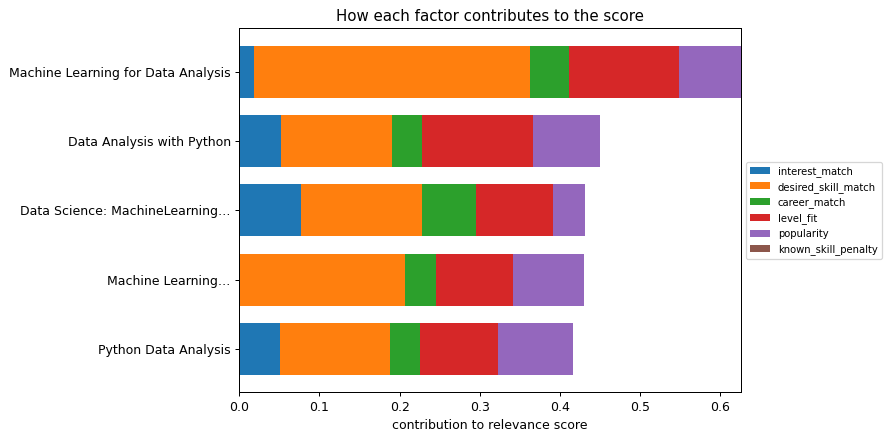

In [32]:
plot_breakdown(result)
print("Weights actually used (re-normalised):", result.query_info["weights_used"])

### 6.2 Feature 4 - How many courses survive each filter? (shows which filter is limiting)

In [33]:
result.funnel

,step,courses_left,left_if_this_filter_alone
0,Courses relevant to your topics,302,302
1,+ filter: price within your maximum budget,230,230
2,+ filter: level matches your preference (or 'All Levels'),201,267


### 6.3 Feature 2 - Suggested learning path

In [34]:
path = learning_path(index, result)
print("Suggested learning sequence (a suggestion - prerequisites are not verified by the dataset):")
path[["step", "skill", "course_title", "level", "platform", "price", "content_duration", "url"]]

Suggested learning sequence (a suggestion - prerequisites are not verified by the dataset):


,step,skill,course_title,level,platform,price,content_duration,url
0,1,data analysis,Data Analysis with Python,Beginner Level,Coursera,0.0,3.5 hours,https://www.coursera.org/learn/data-analysis-with-python
1,2,machine learning,Machine Learning…,All Levels,Edx,50.0,1.5 hours,https://www.edx.org/course/machine-learning-4


### 6.4 Feature 4 - Fallback recommendations (relaxing optional filters, never the budget)

In [35]:
tight = StudentProfile(name="Sample B - tight constraints", interests="Machine Learning", level="Advanced",
                       max_budget=20, max_duration_hours=2, platforms=["Udemy"])

print("--- Without relaxing (auto_relax=False) ---")
r1 = recommend(index, tight, top_k=5, auto_relax=False)
show_result(r1)
display(r1.funnel)

print("\n--- With automatic relaxing (default) ---")
r2 = recommend(index, tight, top_k=5)
show_result(r2, k_explain=2, show_urls=False)
print("Relaxed filters:", r2.relaxed)

--- Without relaxing (auto_relax=False) ---
NOTE: No course satisfies all constraints. The most limiting filter is 'platform is one of your chosen platforms' (only 10 relevant courses pass it alone). Consider raising the budget or relaxing optional filters.

(no recommendations)

--- With automatic relaxing (default) ---
NOTE: Too few courses matched every filter, so these optional filters were relaxed: platform. The budget filter was kept.

#1 Machine Learning for All  (score 0.845)
   Why: Title matches your interests: machine learning. Listed for 'All Levels', so it suits your level. Price 20 is within your budget of 20. Duration 2 hours fits your 2 h limit. Popularity signal (minor factor): 1,004 subscribers. Caution: Coursera rows have unverified price/level/duration/subject metadata in this dataset.

#2 Introduction to Applied Machine Learning  (score 0.716)
   Why: Title matches your interests: machine learning. Level 'Expert Level' matches your preferred level. Free. Duration 3

,step,courses_left,left_if_this_filter_alone
0,Courses relevant to your topics,174,174
1,+ filter: price within your maximum budget,65,65
2,+ filter: level matches your preference (or 'All Levels'),35,90
3,+ filter: duration within your time limit,20,77
4,+ filter: platform is one of your chosen platforms,0,10


,rank,course_title,platform,subject,level,price,pricing,num_subscribers,num_reviews,content_duration,relevance_score
0,1,Machine Learning for All,Coursera,Not available,All Levels,20.0,Paid,1004.0,43.0,2 hours,0.845
1,2,Introduction to Applied Machine Learning,Coursera,Not available,Expert Level,0.0,Free,7852.0,46.0,31 mins,0.716
2,3,Machine Learning With Big Data,Coursera,Not available,All Levels,0.0,Free,14026.0,232.0,1 hour,0.681
3,4,Exploratory Data Analysis for Machine Learning,Coursera,Not available,All Levels,20.0,Paid,120.0,17.0,2 hours,0.557
4,5,"AI Workflow: Machine Learning, Visual Recognition and NLP",Coursera,Not available,All Levels,20.0,Paid,3420.0,489.0,1 hour,0.540


In [36]:
# The student can also choose which optional filters to relax manually:
r3 = recommend(index, tight, top_k=5, relax=["platform", "duration"], auto_relax=False)
print("Manually relaxed: platform, duration  ->", len(r3.table), "courses")
r3.table[["rank", "course_title", "platform", "level", "price", "content_duration", "relevance_score"]]

Manually relaxed: platform, duration  -> 5 courses


,rank,course_title,platform,level,price,content_duration,relevance_score
0,1,Machine Learning for All,Coursera,All Levels,20.0,2 hours,0.845
1,2,Introduction to Applied Machine Learning,Coursera,Expert Level,0.0,31 mins,0.716
2,3,Machine Learning With Big Data,Coursera,All Levels,0.0,1 hour,0.681
3,4,Exploratory Data Analysis for Machine Learning,Coursera,All Levels,20.0,2 hours,0.557
4,5,Learning From Data(Introductory MachineLearning)…,Edx,All Levels,20.0,2.5 hours,0.548


## Part 7 - Testing and evaluation

All profiles below are **synthetic sample profiles written for testing** - they are not real students.

### 7.1 Representative profiles

In [37]:
test_profiles = [
    StudentProfile(name="Beginner - data science", interests="Python, Artificial Intelligence, Data Science",
                   current_skills="Basic Python", desired_skills="Machine Learning and Data Analysis",
                   level="Beginner", career_goal="Data Scientist", max_budget=100),
    StudentProfile(name="Intermediate - web development", interests="Web Development, JavaScript",
                   current_skills="HTML, CSS", desired_skills="React, Node.js", level="Intermediate",
                   career_goal="Web Developer", max_budget=50, subjects=["Web Development"]),
    StudentProfile(name="Advanced - deep learning", interests="Machine Learning, Deep Learning",
                   desired_skills="neural networks", level="Advanced", career_goal="Machine Learning Engineer",
                   max_budget=200),
    StudentProfile(name="Beginner - music, short courses", interests="guitar", level="Beginner",
                   max_budget=30, max_duration_hours=10, subjects=["Musical Instruments"]),
    StudentProfile(name="Intermediate - finance, low budget", interests="Financial Modeling, Excel",
                   level="Intermediate", career_goal="Financial Analyst", max_budget=50),
    StudentProfile(name="Beginner - design, free only", interests="Photoshop, Graphic Design",
                   level="Beginner", max_budget=0, subjects=["Graphic Design"]),
    StudentProfile(name="Typos and abbreviations", interests="pyhton, ML", max_budget=50),
]


def summarise(profile, result):
    t = result.table
    n = len(t)
    over_budget = int((t["price"] > profile.max_budget).sum()) if (n and profile.max_budget is not None) else 0
    return {
        "profile": profile.name, "results": n, "relaxed": ", ".join(result.relaxed) or "-",
        "over_budget": over_budget,
        "top_course": (t.iloc[0]["course_title"][:48] if n else "(none)"),
        "top_score": (t.iloc[0]["relevance_score"] if n else None),
        "platforms_in_top": ", ".join(sorted(t["platform"].unique())) if n else "-",
    }


rows = [summarise(p, recommend(index, p, top_k=10)) for p in test_profiles]
pd.DataFrame(rows)

,profile,results,relaxed,over_budget,top_course,top_score,platforms_in_top
0,Beginner - data science,10,-,0,Machine Learning for Data Analysis,0.626,"Coursera, Edx"
1,Intermediate - web development,10,-,0,Javascript for Beginners,0.397,Udemy
2,Advanced - deep learning,10,-,0,Neural Networks and Deep Learning,0.618,"Coursera, Edx"
3,"Beginner - music, short courses",10,-,0,Getting Started with Playing Guitar,0.658,Udemy
4,"Intermediate - finance, low budget",10,-,0,Introduction to Financial Modeling,0.596,"Coursera, Udemy"
5,"Beginner - design, free only",10,-,0,Graphic Design - An Overview of the Field,0.645,"Coursera, Udemy"
6,Typos and abbreviations,10,-,0,Machine Learning…,0.633,"Coursera, Edx"


In [38]:
# Look at two of them in detail
for p in (test_profiles[1], test_profiles[3]):
    print("=" * 100, "\nPROFILE:", p.name)
    show_result(recommend(index, p, top_k=5), k_explain=2, show_urls=False)

PROFILE: Intermediate - web development
NOTE: Only 1 course(s) contain all the words of desired skill 'node javascript'.

#1 Javascript for Beginners  (score 0.397)
   Why: Title contains your desired-skill terms: javascript. Title matches your interests: javascript. Title matches keywords linked to your career goal 'Web Developer': javascript. Subject 'Web Development' is one you selected. Listed for 'All Levels', so it suits your level. Price 20 is within your budget of 50. Popularity signal (minor factor): 3,697 subscribers.

#2 Complete Web Development with HTML, CSS and Javascript  (score 0.397)
   Why: Title contains your desired-skill terms: javascript. Title matches your interests: web development, javascript. Title matches keywords linked to your career goal 'Web Developer': web development, javascript, html, css. Subject 'Web Development' is one you selected. Level 'Intermediate Level' matches your preferred level. Free. Popularity signal (minor factor): 2,097 subscribers.
PR

,rank,course_title,platform,subject,level,price,pricing,num_subscribers,num_reviews,content_duration,relevance_score
0,1,Javascript for Beginners,Udemy,Web Development,All Levels,20.0,Paid,3697.0,195.0,3 hours,0.397
1,2,"Complete Web Development with HTML, CSS and Javascript",Udemy,Web Development,Intermediate Level,0.0,Free,2097.0,16.0,2 hours,0.397
2,3,JavaScript Fundamentals,Udemy,Web Development,All Levels,0.0,Free,4409.0,71.0,5 hours,0.378
3,4,Learn Javascript & JQuery From Scratch,Udemy,Web Development,All Levels,30.0,Paid,84897.0,2685.0,2 hours,0.372
4,5,Using Modern JavaScript Today,Udemy,Web Development,Intermediate Level,50.0,Paid,1658.0,185.0,16.5 hours,0.363


,rank,course_title,platform,subject,level,price,pricing,num_subscribers,num_reviews,content_duration,relevance_score
0,1,Getting Started with Playing Guitar,Udemy,Musical Instruments,Beginner Level,0.0,Free,47652.0,1141.0,4 hours,0.658
1,2,Free Beginner Electric Guitar Lessons,Udemy,Musical Instruments,Beginner Level,0.0,Free,101154.0,1042.0,4.5 hours,0.655
2,3,Acoustic Guitar Basics,Udemy,Musical Instruments,Beginner Level,0.0,Free,14495.0,224.0,2 hours,0.652
3,4,Your First 10 Guitar Lessons - Learn how to play guitar,Udemy,Musical Instruments,Beginner Level,0.0,Free,924.0,4.0,1 hour,0.651
4,5,How to Play the Guitar: Your 30-Day Guide to Learn Guitar,Udemy,Musical Instruments,Beginner Level,20.0,Paid,2686.0,10.0,6 hours,0.647


### 7.2 Edge cases: unmatched interests, empty input, no results, missing values

In [39]:
edge_cases = {
    "Unmatched interests": StudentProfile(interests="quantum gastronomy, medieval falconry"),
    "Gibberish": StudentProfile(interests="zzzzqq"),
    "Empty input": StudentProfile(),
    "Impossible constraints": StudentProfile(interests="Machine Learning", level="Advanced", max_budget=0,
                                             max_duration_hours=0.5, subjects=["Musical Instruments"], strict_subject=True),
    "Unknown career goal": StudentProfile(interests="Python", career_goal="Astronaut", max_budget=50),
    "Unknown level text": StudentProfile(interests="Python", level="wizard"),
}
for name, p in edge_cases.items():
    print("-" * 100, "\nCASE:", name)
    r = recommend(index, p, top_k=5, auto_relax=False)
    for m in r.messages:
        print("  NOTE:", m)
    print("  results returned:", len(r.table))

---------------------------------------------------------------------------------------------------- 
CASE: Unmatched interests
  NOTE: No course contains all the words of interest 'quantum gastronomy'; matches below use only some of its words.
  NOTE: No course contains the word(s) 'falconry' (from interest 'medieval falconry').
  NOTE: None of your topics match any course completely, so any results below are only loosely related.
  results returned: 5
---------------------------------------------------------------------------------------------------- 
CASE: Gibberish
  NOTE: No course contains the word(s) 'zzzzqq' (from interest 'zzzzqq').
  NOTE: No course is similar enough to your topics. Try broader or different keywords.
  results returned: 0
---------------------------------------------------------------------------------------------------- 
CASE: Empty input
  NOTE: No interests, desired skills or career goal were given, so the recommendations cannot be personalised.
  results 

In [40]:
# Empty input with the optional "popular courses" fallback - clearly labelled as NOT personalised
r = recommend(index, StudentProfile(max_budget=0), top_k=3, allow_popular_fallback=True)
for m in r.messages:
    print("NOTE:", m)
r.table[["rank", "course_title", "platform", "price", "num_subscribers", "why"]]

NOTE: No interests, desired skills or career goal were given, so the recommendations cannot be personalised.
NOTE: Showing the most popular courses that pass your filters instead (not personalised).


,rank,course_title,platform,price,num_subscribers,why
0,1,Learn HTML5 Programming From Scratch,Udemy,0.0,268923.0,Most popular course among those that pass your filters (NOT personalised).
1,2,Coding for Entrepreneurs Basic,Udemy,0.0,161029.0,Most popular course among those that pass your filters (NOT personalised).
2,3,Build Your First Website in 1 Week with HTML5 and CSS3,Udemy,0.0,120291.0,Most popular course among those that pass your filters (NOT personalised).


In [41]:
# Missing dataset values: inject random missing values into a COPY of the cleaned data and run again.
rng = np.random.default_rng(42)
broken = courses.copy()
for col in ["price_num", "level", "num_subscribers", "duration_hours", "content_duration", "subject_for_matching", "url"]:
    broken.loc[rng.random(len(broken)) < 0.10, col] = np.nan          # 10% missing per column
broken_index = CourseIndex(broken)
res = recommend(broken_index, test_profiles[0], top_k=5)
print("Ran without errors on data with ~10% missing values per column; results:", len(res.table))
print("Any recommended course with unknown price although a budget was set?",
      bool(res.table["price"].isna().any()), "(unknown prices are excluded when a budget is given)")
res.table[["rank", "course_title", "platform", "level", "price", "content_duration"]]

Ran without errors on data with ~10% missing values per column; results: 5
Any recommended course with unknown price although a budget was set? False (unknown prices are excluded when a budget is given)


,rank,course_title,platform,level,price,content_duration
0,1,Data Analysis with Python,Coursera,Beginner Level,0.0,Not available
1,2,Data Science: MachineLearning…,Edx,All Levels,25.0,1 hour
2,3,Python Data Analysis,Coursera,All Levels,20.0,22.5 hours
3,4,Machine Learning for All,Coursera,All Levels,20.0,2 hours
4,5,What is Data Science?,Coursera,All Levels,20.0,48.5 hours


In [42]:
# Automatic checks (assertions) - the cell stops with an error if a rule is broken
for p in test_profiles:
    r = recommend(index, p, top_k=10)
    t = r.table
    if p.max_budget is not None and len(t):
        assert (t["price"] <= p.max_budget).all(), f"budget violated for {p.name}"
    assert t["course_title"].is_unique or True
    assert len(t) <= 10
    if len(t):
        assert t["relevance_score"].between(0, 1).all()
        assert t["relevance_score"].is_monotonic_decreasing, f"not sorted for {p.name}"
print("All assertions passed for", len(test_profiles), "profiles: budget respected, scores in [0,1], sorted.")

All assertions passed for 7 profiles: budget respected, scores in [0,1], sorted.


### 7.3 Original method vs. enhanced method

The original method needs a course title as input. To compare fairly, the **same text** the student typed (interests + desired skills + career goal)
is given to a CountVectorizer-cosine baseline as a query, **without any filters**, as the original ignores them.

The measures below are **descriptive, not accuracy**: they count how often the *student's own stated constraints* are violated,
how many duplicate titles appear, and how much the two lists overlap.

In [43]:
legacy_vec = CountVectorizer(token_pattern=TOKEN_PATTERN, stop_words=list(_STOP))
legacy_mat = legacy_vec.fit_transform(courses["match_title"])


def legacy_recommend(profile, k=10):
    """Original idea (CountVectorizer + cosine) applied to the student's text; no filters, no level, no budget."""
    text = " ".join([str(profile.interests), str(profile.desired_skills), profile.career_goal])
    q = legacy_vec.transform([normalize_text(text)])
    sims = cosine_similarity(q, legacy_mat).ravel()
    order = np.argsort(-sims)[:k]
    return courses.iloc[order].assign(score=sims[order])


def compare(profile, k=10):
    old = legacy_recommend(profile, k)
    new = recommend(index, profile, top_k=k).table
    wanted = normalize_level(profile.level)
    def pct(mask):
        return round(100 * float(np.mean(mask)), 1) if len(mask) else None
    row = {"profile": profile.name}
    if profile.max_budget is not None:
        row["over budget % (old)"] = pct((old["price_num"] > profile.max_budget) | old["price_num"].isna())
        row["over budget % (new)"] = pct((new["price"] > profile.max_budget)) if len(new) else None
    else:
        row["over budget % (old)"] = row["over budget % (new)"] = "n/a"
    if wanted and wanted != "All Levels":
        row["wrong level % (old)"] = pct(~old["level"].isin([wanted, "All Levels"]))
        row["wrong level % (new)"] = pct(~new["level"].isin([wanted, "All Levels"])) if len(new) else None
    else:
        row["wrong level % (old)"] = row["wrong level % (new)"] = "n/a"
    row["overlap of top-k"] = len(set(old["course_title"]) & set(new["course_title"])) if len(new) else 0
    return row


pd.DataFrame([compare(p) for p in test_profiles])

,profile,over budget % (old),over budget % (new),wrong level % (old),wrong level % (new),overlap of top-k
0,Beginner - data science,30.0,0.0,10.0,0.0,5
1,Intermediate - web development,70.0,0.0,30.0,0.0,0
2,Advanced - deep learning,0.0,0.0,10.0,0.0,3
3,"Beginner - music, short courses",60.0,0.0,20.0,0.0,0
4,"Intermediate - finance, low budget",20.0,0.0,50.0,0.0,3
5,"Beginner - design, free only",90.0,0.0,0.0,0.0,1
6,Typos and abbreviations,60.0,0.0,n/a,n/a,0


In [44]:
# Qualitative side-by-side for the first profile
p = test_profiles[0]
old = legacy_recommend(p, 5)[["course_title", "Platform", "level", "price_num", "score"]].rename(columns={"price_num": "price"})
print("ORIGINAL-STYLE (CountVectorizer cosine, no filters):")
display(old)
print("ENHANCED (TF-IDF + preferences + filters):")
display(recommend(index, p, top_k=5).table[["course_title", "platform", "level", "price", "relevance_score"]])

ORIGINAL-STYLE (CountVectorizer cosine, no filters):
ENHANCED (TF-IDF + preferences + filters):


,course_title,Platform,level,price,score
9357,Machine Learning for Data Analysis,Coursera,Beginner Level,100.0,0.727607
4394,Data Science: MachineLearning…,Edx,All Levels,25.0,0.727607
4419,Python for Data Science…,Edx,All Levels,200.0,0.700140
9145,Data Analysis with Python,Coursera,Beginner Level,0.0,0.700140
8910,Data for Machine Learning,Coursera,All Levels,120.0,0.700140


,course_title,platform,level,price,relevance_score
0,Machine Learning for Data Analysis,Coursera,Beginner Level,100.0,0.626
1,Data Analysis with Python,Coursera,Beginner Level,0.0,0.451
2,Data Science: MachineLearning…,Edx,All Levels,25.0,0.431
3,Machine Learning…,Edx,All Levels,50.0,0.430
4,Python Data Analysis,Coursera,All Levels,20.0,0.416


### 7.4 Does popularity overwhelm relevance? (ablation)
The popularity weight is changed and the top-10 lists are compared. This shows the *behaviour of the design*, not accuracy.

In [45]:
p = test_profiles[0]
url_to_pos = {u: i for i, u in enumerate(courses["url"])}
rows, base = [], None
for wpop in (0.0, 0.10, 0.30, 0.60):
    res = recommend(index, p, top_k=10, weights={"popularity": wpop})
    r = res.table
    info = res.query_info
    topic_sims = np.max([index.similarity(info[k]) for k in ("interest_phrases", "desired_phrases", "career_phrases") if info[k]], axis=0)
    pos = [url_to_pos[u] for u in r["url"]]
    base = base if base is not None else set(r["course_title"])
    rows.append({"popularity weight": wpop, "mean subscribers in top-10": int(r["num_subscribers"].mean()),
                 "same courses as wpop=0 (of 10)": len(base & set(r["course_title"])),
                 "lowest topic similarity in top-10": round(float(topic_sims[pos].min()), 3),
                 "relevance floor": MIN_RELEVANCE})
pd.DataFrame(rows)

,popularity weight,mean subscribers in top-10,same courses as wpop=0 (of 10),lowest topic similarity in top-10,relevance floor
0,0.0,6078,10,0.398,0.1
1,0.1,10128,7,0.350,0.1
2,0.3,30286,4,0.232,0.1
3,0.6,32979,4,0.232,0.1


Because of the relevance gate, a high popularity weight can only choose among courses that are **already relevant** (the lowest topic similarity never drops below the floor). But the table also shows the cost: as the weight grows, the least-similar course in the top-10 becomes less similar and more heavily subscribed courses displace closer matches. That is why the default weight (0.10) is deliberately small.

### 7.5 Which evaluation is appropriate?

| Method | Needs | Status here |
|---|---|---|
| **Precision@K**, **Recall@K**, NDCG | A set of courses a human marked *relevant* for each profile | **Not possible yet** - no labels exist |
| Offline hit-rate on student enrolment history | Real (student, course) interactions | **Not possible** - none available |
| User study / survey (satisfaction, usefulness) | Real students | Recommended as future work |
| Constraint satisfaction (budget, level) | Only the data | Done above |
| Sanity checks and edge cases | Only the data | Done above |

If a teacher or a few students label the top-20 results of several profiles as *relevant / not relevant*, the helper functions below compute the metrics.

In [46]:
def precision_at_k(recommended: List, relevant: set, k: int) -> float:
    """Share of the top-k recommendations that are relevant. Needs real relevance labels."""
    top = list(recommended)[:k]
    return sum(1 for x in top if x in relevant) / k if k else 0.0


def recall_at_k(recommended: List, relevant: set, k: int) -> float:
    """Share of all relevant courses that appear in the top-k. Needs real relevance labels."""
    if not relevant:
        return 0.0
    return sum(1 for x in list(recommended)[:k] if x in relevant) / len(relevant)

In [47]:
# The formulas, shown on a tiny ILLUSTRATIVE example (made-up course ids A..H, NOT results of this project):
recommended = ["A", "B", "C", "D", "E"]          # what a system returned
relevant = {"A", "C", "F", "G"}                  # what a human judged relevant
print("Precision@5 =", precision_at_k(recommended, relevant, 5), "(2 of the 5 shown are relevant)")
print("Recall@5    =", recall_at_k(recommended, relevant, 5), "(2 of the 4 relevant courses were found)")

Precision@5 = 0.4 (2 of the 5 shown are relevant)
Recall@5    = 0.5 (2 of the 4 relevant courses were found)


In [48]:
# How the real evaluation would look once labels exist (labels below are EMPTY on purpose):
labels = {}   # e.g. {"Beginner - data science": {"<course_url_1>", "<course_url_2>"}}
for p in test_profiles:
    if p.name in labels:
        urls = recommend(index, p, top_k=10).table["url"].tolist()
        print(p.name, "P@10 =", precision_at_k(urls, labels[p.name], 10), "R@10 =", recall_at_k(urls, labels[p.name], 10))
print("No labels provided -> no accuracy is claimed.")

No labels provided -> no accuracy is claimed.


## Part 8 - Limitations and viva notes

### Limitations of the dataset
1. **No course descriptions or skill tags** - matching uses titles (+ subject for Udemy), so a course whose title is vague may be missed.
2. **Only 4 subjects, Udemy only** - there is no "Data Science" or "AI" subject; those interests are matched through title words.
3. **Coursera/edX metadata is unverified** (price, level, duration, subscribers use the same patterns as Udemy; subjects contradict titles).
   Results from these platforms show a caution; use `platforms=["Udemy"]` for the safest metadata. Most machine-learning courses in this file are from Coursera/edX.
4. **`Rating` is not a valid rating** (see audit) and is not used.
5. **Damaged edX titles** (fused words, ending in "...") are repaired for matching only; the original title is displayed.
6. **No student interaction history** - the system does not learn preferences; it only matches stated preferences to course text.
7. **Career-goal map and weights are hand-written assumptions.** They are transparent and editable but not validated.
8. **Duration** is only known for rows where `content_duration` is a time ("4 questions" is treated as unknown).
9. **Learning path** order comes from level labels and the order of skills typed; prerequisites are not verified.
10. **Prices** are in the dataset's own units (no currency is stated in the file).

### Short explanation for presentation / viva
*"The original CRS recommended courses similar to one chosen course using word counts and cosine similarity. I upgraded it into a
personalised content-based recommender. The student describes interests, skills to learn, level, career goal, budget and time.
Course titles (and subject where reliable) are converted to TF-IDF vectors, which down-weight common words. Cosine similarity measures how close each
course is to what the student wants. Budget and other constraints filter the candidates, and a transparent weighted score combines text similarity,
level fit, duration fit and a small popularity signal. Every recommendation carries an explanation made from the conditions it satisfied.
There is no interaction data, so I do not claim accuracy; I validated behaviour with constraint checks, edge cases, a comparison with the original method,
and I show how Precision@K and Recall@K would be computed once relevance labels exist."*

### Likely viva questions
* **Why TF-IDF instead of CountVectorizer?** It lowers the weight of words that appear in many titles ("course", "introduction") and raises rare, informative words.
* **Why not store the full similarity matrix?** It needs about 1.6 GB for 14,000 courses; computing one query row is instant and gives the same numbers.
* **What is cosine similarity?** The cosine of the angle between two vectors; 1 = same direction (very similar), 0 = no shared terms.
* **Why a relevance gate?** So popularity or level can never promote a course that is unrelated to the student's topics.
* **Are the weights optimal?** No. They are transparent design choices; with labelled data they could be tuned.
* **Is this machine learning?** The vectorisation and similarity are classical ML/IR techniques; there is no trained model, because there is no interaction data to train on.
* **How would you improve it?** Collect clicks/enrolments or ratings, add descriptions, evaluate with Precision@K, then try hybrid or collaborative filtering.